### Support Vector Machine

Apply a linear SVM to the Iris dataset. Plot the data and decision boundary.

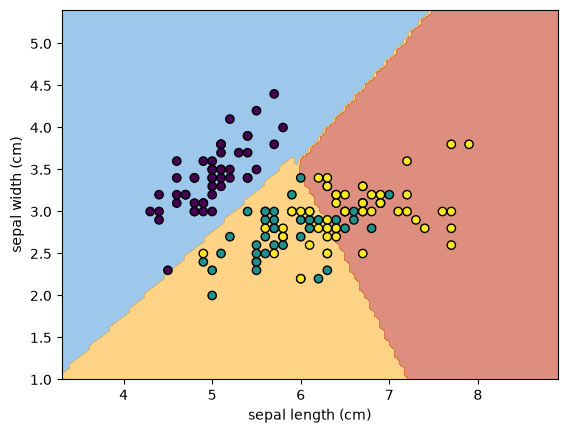

In [1]:
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data[:, :2]
y = iris.target

model = SVC(kernel="linear", C=1.0)
model.fit(X, y)

DecisionBoundaryDisplay.from_estimator(model, X, response_method="predict", xlabel=iris.feature_names[0], ylabel=iris.feature_names[1], alpha=0.5)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k")
plt.show()

 Train a linear SVM for the given positive and negative points. Plot the separating hyperplane.

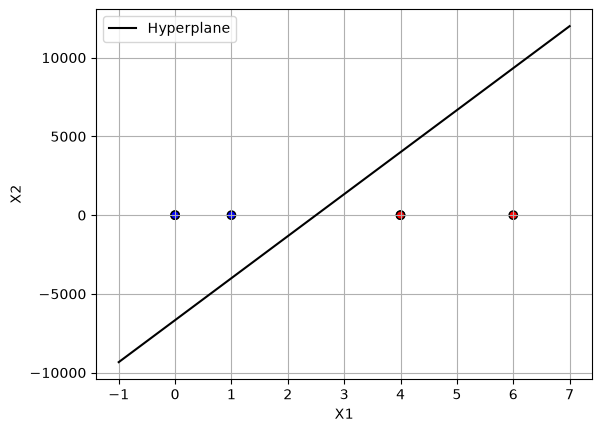

w = [ 6.6675e-01 -2.5000e-04] b = -1.6669166666666666


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

X = np.array([[4, 1], [4, -1], [6, 0], [1, 0], [0, 1], [0, -1]])
y = np.array([1, 1, 1, -1, -1, -1])

model = SVC(kernel="linear", C=1e6)
model.fit(X, y)

w = model.coef_[0]
b = model.intercept_[0]

xx = np.linspace(-1, 7, 200)
yy = -(w[0] * xx + b) / w[1]

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
plt.plot(xx, yy, "k-", label="Hyperplane")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid()
plt.legend()
plt.show()

print("w =", w, "b =", b)

Draw the maximum-margin hyperplane manually, without scikit-learn.

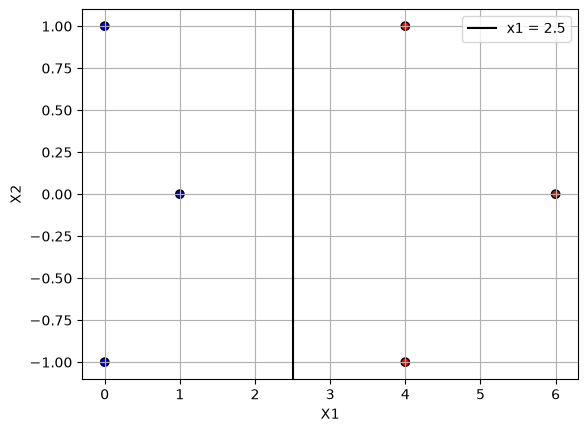

Hyperplane: x1 - 2.5 = 0


In [3]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[4, 1], [4, -1], [6, 0], [1, 0], [0, 1], [0, -1]])
y = np.array([1, 1, 1, -1, -1, -1])

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
plt.axvline(2.5, color="k", label="x1 = 2.5")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid()
plt.legend()
plt.show()

print("Hyperplane: x1 - 2.5 = 0")

Plot the hyperplane and the three regions for the given expressions. Find the slope and intercept.

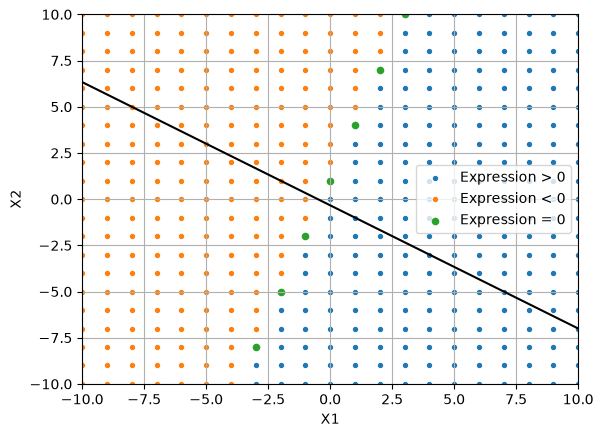

Slope = -0.6666666666666666 Intercept = -0.3333333333333333


In [4]:
import numpy as np
import matplotlib.pyplot as plt

x1 = np.arange(-10, 11, 1)
x2 = np.arange(-10, 11, 1)
X1, X2 = np.meshgrid(x1, x2)

boundary = 1 + 2*X1 + 3*X2
region = 1 + 3*X1 - X2

plt.contour(X1, X2, boundary, levels=[0], colors="black")
plt.scatter(X1[region > 0], X2[region > 0], s=8, label="Expression > 0")
plt.scatter(X1[region < 0], X2[region < 0], s=8, label="Expression < 0")
plt.scatter(X1[np.isclose(region, 0)], X2[np.isclose(region, 0)], s=20,
            label="Expression = 0")

plt.xlabel("X1")
plt.ylabel("X2")
plt.grid()
plt.legend()
plt.show()

print("Slope =", -2/3, "Intercept =", -1/3)

 Plot both hyperplanes and indicate the positive and negative regions. Find their slopes and intercepts.

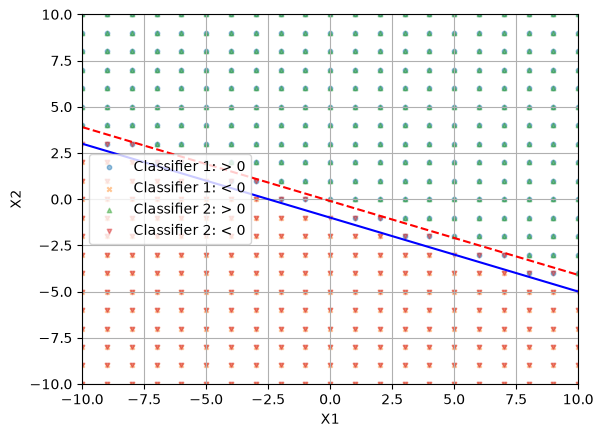

Classifier 1: slope = -0.4 intercept = -1
Classifier 2: slope = -0.4 intercept = -0.1
The hyperplanes are parallel but distinct.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

x1 = np.arange(-10, 11, 1)
x2 = np.arange(-10, 11, 1)
X1, X2 = np.meshgrid(x1, x2)

F1 = 5 + 2*X1 + 5*X2
F2 = 5 + 20*X1 + 50*X2

plt.scatter(X1[F1 > 0], X2[F1 > 0], s=10, marker="o", alpha=0.45,
            label="Classifier 1: > 0")
plt.scatter(X1[F1 < 0], X2[F1 < 0], s=10, marker="x", alpha=0.45,
            label="Classifier 1: < 0")
plt.scatter(X1[F2 > 0], X2[F2 > 0], s=10, marker="^", alpha=0.45,
            label="Classifier 2: > 0")
plt.scatter(X1[F2 < 0], X2[F2 < 0], s=10, marker="v", alpha=0.45,
            label="Classifier 2: < 0")

plt.contour(X1, X2, F1, levels=[0], colors="blue")
plt.contour(X1, X2, F2, levels=[0], colors="red", linestyles="--")

plt.xlabel("X1")
plt.ylabel("X2")
plt.grid()
plt.legend()
plt.show()

print("Classifier 1: slope =", -2/5, "intercept =", -1)
print("Classifier 2: slope =", -2/5, "intercept =", -1/10)
print("The hyperplanes are parallel but distinct.")

**Additional Q1.** Use scikit-learn to plot both given hyperplanes and their regions.

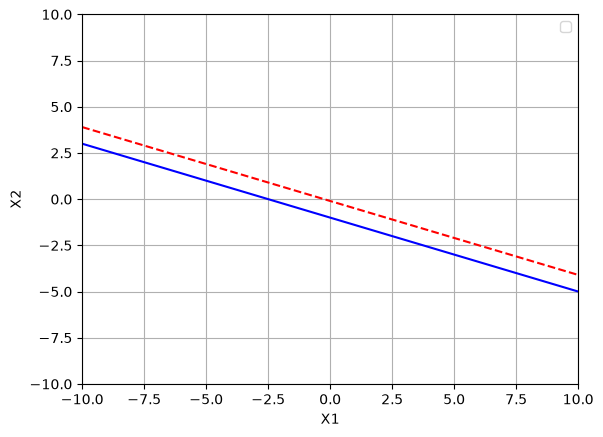

Classifier 1 coefficients: [3.99975359 9.99926076] 8.999322367059124
Classifier 2 coefficients: [3.99975428 9.99926284] 1.0000491440353


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

x1 = np.arange(-10, 11, 1)
x2 = np.arange(-10, 11, 1)
X1, X2 = np.meshgrid(x1, x2)

F1 = 5 + 2*X1 + 5*X2
F2 = 5 + 20*X1 + 50*X2

X = np.column_stack((X1.ravel(), X2.ravel()))

y1 = np.where(F1.ravel() > 0, 1, -1)
y2 = np.where(F2.ravel() > 0, 1, -1)

model1 = SVC(kernel="linear", C=1e6).fit(X, y1)
model2 = SVC(kernel="linear", C=1e6).fit(X, y2)

plt.contour(X1, X2, F1, levels=[0], colors="blue")
plt.contour(X1, X2, F2, levels=[0], colors="red", linestyles="--")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid()
plt.legend(["Classifier 1", "Classifier 2"])
plt.show()

print("Classifier 1 coefficients:", model1.coef_[0], model1.intercept_[0])
print("Classifier 2 coefficients:", model2.coef_[0], model2.intercept_[0])

**Additional Q2.** Apply linear, polynomial, RBF and sigmoid kernels to Iris. Plot the data and decision boundaries.

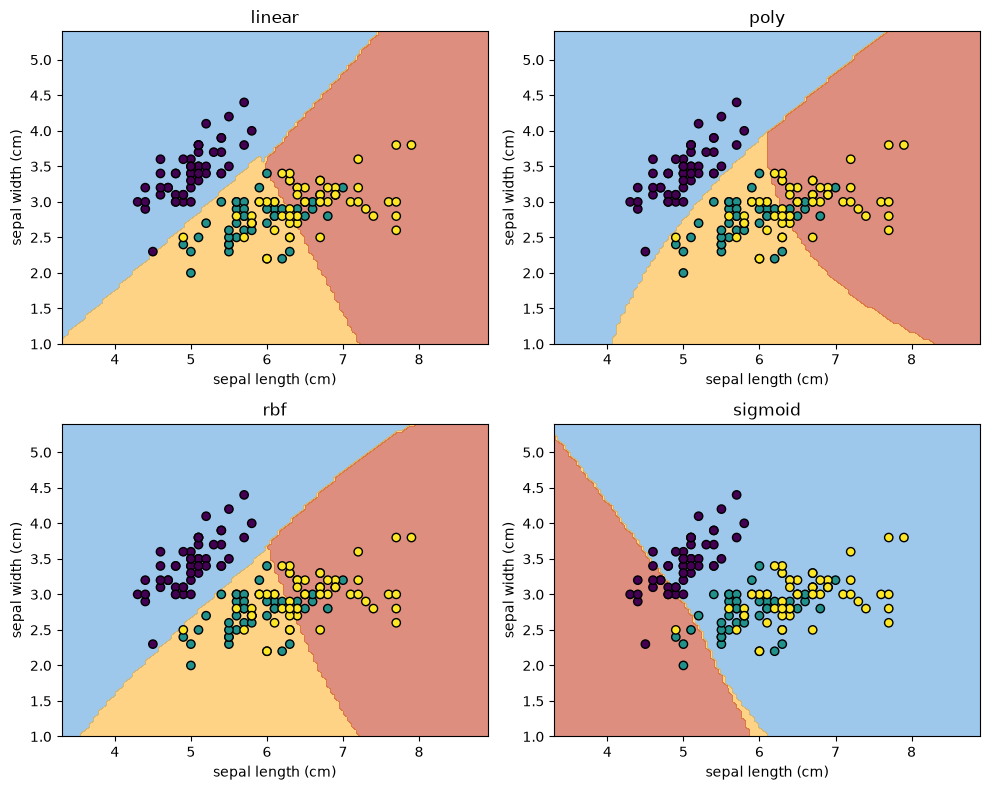

In [7]:
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data[:, :2]
y = iris.target

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, kernel in zip(axes.ravel(), ["linear", "poly", "rbf", "sigmoid"]):
    model = SVC(kernel=kernel, C=1.0, gamma="scale")
    model.fit(X, y)

    DecisionBoundaryDisplay.from_estimator(
        model, X, response_method="predict", ax=ax, alpha=0.5
    )
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k")
    ax.set_title(kernel)
    ax.set_xlabel(iris.feature_names[0])
    ax.set_ylabel(iris.feature_names[1])

plt.tight_layout()
plt.show()